C:\Users\super\AppData\Local\Temp\ipykernel_16948\2835960023.py:17: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.hist(img.flatten(), 256, [0,256], color='r')
C:\Users\super\AppData\Local\Temp\ipykernel_16948\2835960023.py:38: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.hist(img2.flatten(), 256, [0,256], color='r')


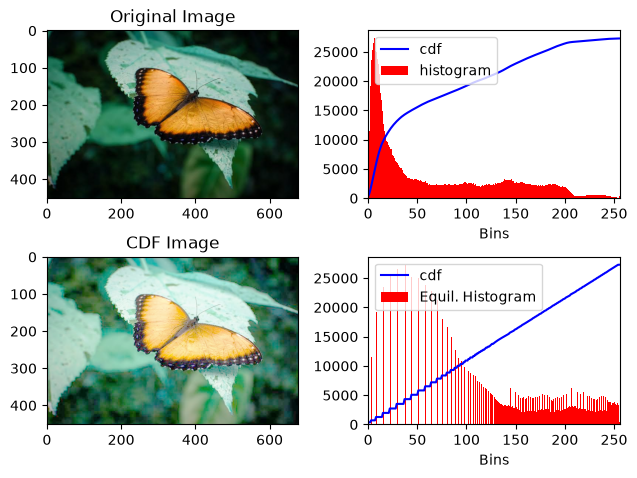

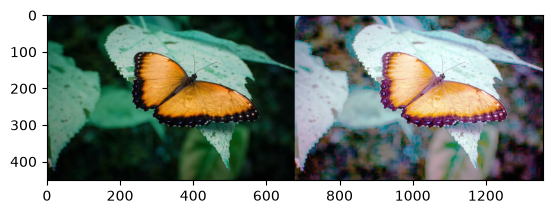

In [1]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

img = cv.imread(r"C:\Users\super\Downloads\images.jpeg")

plt.subplot(221)
plt.title('Original Image')
plt.imshow(img)

hist, bins = np.histogram(img.flatten(), 256, [0,256])
cdf = hist.cumsum()
cdf_n = cdf * hist.max() / cdf.max()

plt.subplot(222)
plt.plot(cdf_n, 'b')
plt.hist(img.flatten(), 256, [0,256], color='r')
plt.xlim([0,256])
plt.legend(('cdf','histogram'), loc='upper left')
plt.xlabel('Bins')

cdf_m = np.ma.masked_equal(cdf, 0)
cdf_m = (cdf_m-cdf_m.min())*255/(cdf_m.max()-cdf_m.min())
cdf = np.ma.filled(cdf_m, 0).astype('uint8')

img2 = cdf[img]

plt.subplot(223)
plt.title('CDF Image')
plt.imshow(img2)

hist, bins = np.histogram(img2.flatten(), 256, [0,256])
cdf = hist.cumsum()
cdf_n = cdf * hist.max() / cdf.max()

plt.subplot(224)
plt.plot(cdf_n, 'b')
plt.hist(img2.flatten(), 256, [0,256], color='r')
plt.xlim([0,256])
plt.legend(('cdf','Equil. Histogram'), loc='upper left')
plt.xlabel('Bins')
plt.tight_layout()
plt.show()

# OpenCV Implementation
equ = cv.merge([cv.equalizeHist(c) for c in cv.split(img)])
res = np.hstack((img, equ))
plt.imshow(res)
plt.show()